# Program 7: Implement an Autoencoder

This notebook demonstrates how to implement a basic convolutional autoencoder using TensorFlow and Keras, train it on the MNIST dataset, and evaluate its image reconstruction performance.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, losses
from tensorflow.keras.models import Model

# Load and preprocess MNIST dataset
(x_train, _), (x_test, _) = tf.keras.datasets.mnist.load_data()

# Normalize pixel values to be between 0 and 1
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Reshape to include channel dimension (28, 28, 1)
x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training shape: (60000, 28, 28, 1)
Testing shape: (10000, 28, 28, 1)


In [2]:
class Autoencoder(Model):
    def __init__(self, latent_dim=32):
        super(Autoencoder, self).__init__()
        self.latent_dim = latent_dim

        # Encoder architecture
        self.encoder = tf.keras.Sequential([
            layers.Input(shape=(28, 28, 1)),
            layers.Conv2D(16, (3, 3), activation='relu', padding='same', strides=2),
            layers.Conv2D(8, (3, 3), activation='relu', padding='same', strides=2),
            layers.Flatten(),
            layers.Dense(latent_dim, activation='relu')
        ])

        # Decoder architecture
        self.decoder = tf.keras.Sequential([
            layers.Input(shape=(latent_dim,)),
            layers.Dense(7 * 7 * 8, activation='relu'),
            layers.Reshape((7, 7, 8)),
            layers.Conv2DTranspose(8, kernel_size=3, strides=2, activation='relu', padding='same'),
            layers.Conv2DTranspose(16, kernel_size=3, strides=2, activation='relu', padding='same'),
            layers.Conv2D(1, kernel_size=(3, 3), activation='sigmoid', padding='same')
        ])

    def call(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

autoencoder = Autoencoder(latent_dim=32)
autoencoder.compile(optimizer='adam', loss=losses.MeanSquaredError())
autoencoder.build(input_shape=(None, 28, 28, 1))
autoencoder.summary()

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 32)             │        13,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 28, 28, 1)      │        14,833 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,729 (112.22 KB)

 Trainable params: 28,729 (112.22 KB)

 Non-trainable params: 0 (0.00 B)

In [3]:
# Train the model
history = autoencoder.fit(
    x_train, x_train,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 49s 201ms/step - loss: 0.0814 - val_loss: 0.0554
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 79s 192ms/step - loss: 0.0433 - val_loss: 0.0332
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 82s 191ms/step - loss: 0.0283 - val_loss: 0.0238
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 45s 192ms/step - loss: 0.0221 - val_loss: 0.0198
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 45s 190ms/step - loss: 0.0191 - val_loss: 0.0177
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 84s 197ms/step - loss: 0.0175 - val_loss: 0.0164
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 45s 191ms/step - loss: 0.0163 - val_loss: 0.0154
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 46s 196ms/step - loss: 0.0155 - val_loss: 0.0148
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 83s 202ms/step - loss: 0.0148 - val_loss: 0.0141
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 45s 192ms/step - loss: 0.0143 - val_loss: 0.0137


313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step


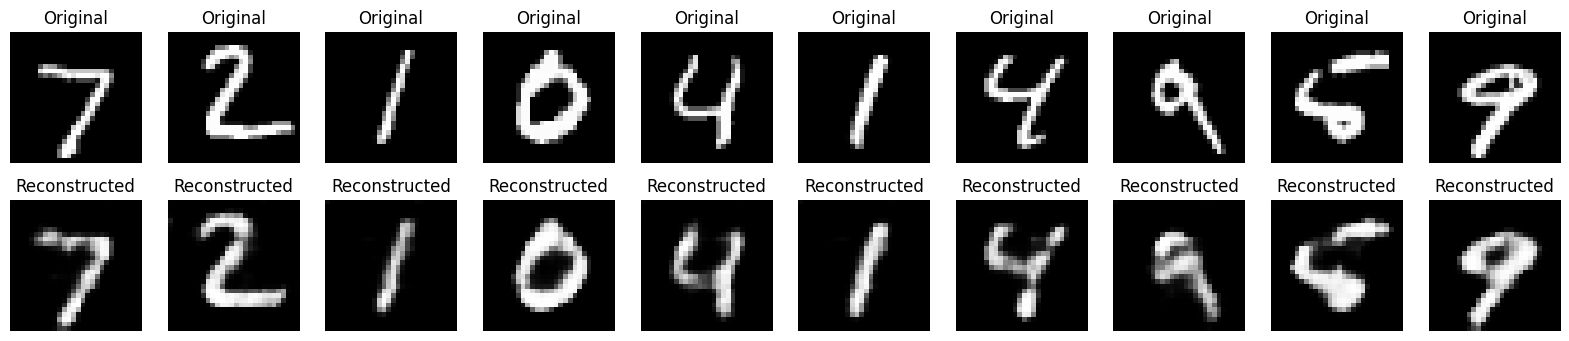

In [4]:
# Reconstruct some test images
reconstructed_images = autoencoder.predict(x_test)

# Visualize reconstruction results
n = 10
plt.figure(figsize=(20, 4))
for i in range(n):
    # Display original images
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(x_test[i].squeeze(), cmap='gray')
    plt.title("Original")
    plt.axis("off")

    # Display reconstruction images
    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(reconstructed_images[i].squeeze(), cmap='gray')
    plt.title("Reconstructed")
    plt.axis("off")
plt.show()